# From SIR to Network Epidemics

## Understanding Disease Spread Through Mathematical Modelling

*A Gentle Introduction*

---

## Why Model Disease?

Disease spread is a **dynamical process** that evolves over time. But it's not unique to epidemiology.

Similar spreading processes appear everywhere:

- 🗣️ **Rumours** spreading through social networks
- 💻 **Computer viruses** infecting machines
- 📱 **Information** cascading through social media
- 📰 **News and trends** going viral
- 🦠 **COVID-19** spreading through populations

### Key Insight

All of these are **spreading processes** that can be represented as dynamical systems.

The same mathematical framework that helps us understand epidemics also applies to:
- Control systems
- Population dynamics
- Chemical reactions
- Information diffusion

## Disease Spread as a Dynamical System

To model any spreading process, we need three fundamental concepts:

### 1. State

At any given time, each individual is in one of several possible states:
- **Susceptible**: can catch the disease
- **Infected**: currently has the disease and can spread it
- **Recovered**: had the disease and is now immune

### 2. Transitions

Individuals move between states according to specific rules:
- Susceptible → Infected (through contact)
- Infected → Recovered (through recovery)

### 3. Time Evolution

The **state of the entire system** changes over time as individuals transition.

This is exactly how we think about:
- Control systems (system states evolving)
- Population dynamics (species populations changing)
- Chemical reactions (reactant concentrations evolving)

## What This Project Covers

This notebook series will progressively build your understanding of epidemic modelling:

### Part 1: Classical SIR Model
Start with the simplest model: ordinary differential equations describing aggregate populations.

### Part 2: SEIR Model
Add a latency period to capture incubation effects.

### Part 3: Network SIR
Move beyond homogeneous mixing to model disease spread on contact networks.

### Part 4: Degree-Based SIR
Account for heterogeneous connectivity using degree distributions.

### Part 5: Agent-Based Models
Simulate individual agents moving and interacting in space.

### Part 6: COVID-19 Case Study
Connect all models to real-world pandemic modelling.

---

### The Narrative Arc

Each model arises from the **limitations** of the previous one:

```
Simple model
     ↓
Observe limitations
     ↓
Introduce new assumptions
     ↓
Develop richer model
     ↓
Repeat
```

By the end, you'll understand:
- **Why** each model exists
- **When** to use each approach
- **How** real pandemic models combine multiple modelling layers

## Setup

Let's import the libraries we'll need throughout this project.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from scipy.integrate import solve_ivp
import pandas as pd

# Set random seed for reproducibility
np.random.seed(42)

# Configure matplotlib
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 10

print("✓ All libraries imported successfully")
print("✓ Ready to start modelling!")

✓ All libraries imported successfully
✓ Ready to start modelling!


## Quick Preview: A Simple Epidemic

Before we dive into the mathematics, let's visualize what an epidemic looks like on a simple network.

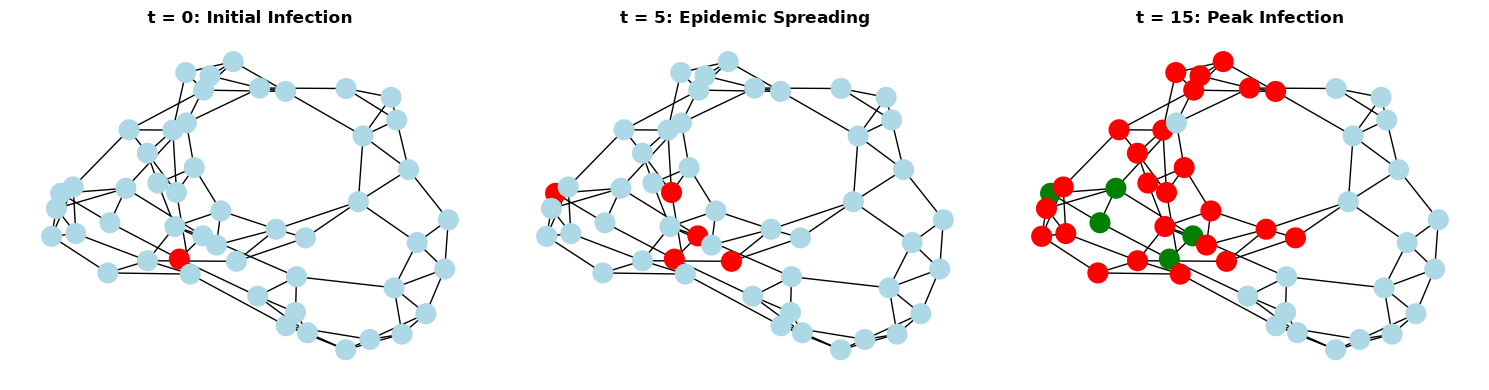

Legend: Blue = Susceptible, Red = Infected, Green = Recovered


In [2]:
# Create a simple network
G = nx.watts_strogatz_graph(n=50, k=4, p=0.1, seed=42)
pos = nx.spring_layout(G, seed=42)

# Simulate a simple spreading process
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Initial state: one infected
node_colors_t0 = ['red' if i == 0 else 'lightblue' for i in range(50)]
nx.draw(G, pos, node_color=node_colors_t0, node_size=200, ax=axes[0], with_labels=False)
axes[0].set_title('t = 0: Initial Infection', fontsize=12, fontweight='bold')
axes[0].axis('off')

# Middle state: spreading
infected = [0, 1, 4, 12, 20]
node_colors_t1 = ['red' if i in infected else 'lightblue' for i in range(50)]
nx.draw(G, pos, node_color=node_colors_t1, node_size=200, ax=axes[1], with_labels=False)
axes[1].set_title('t = 5: Epidemic Spreading', fontsize=12, fontweight='bold')
axes[1].axis('off')

# Final state: many infected
infected_final = list(range(30))
recovered = list(range(5))
node_colors_t2 = ['green' if i in recovered else 'red' if i in infected_final else 'lightblue' 
                  for i in range(50)]
nx.draw(G, pos, node_color=node_colors_t2, node_size=200, ax=axes[2], with_labels=False)
axes[2].set_title('t = 15: Peak Infection', fontsize=12, fontweight='bold')
axes[2].axis('off')

plt.tight_layout()
plt.show()

print("Legend: Blue = Susceptible, Red = Infected, Green = Recovered")

## Next Steps

Now that we've seen what epidemic spread looks like, we're ready to build mathematical models.

**Continue to Notebook 01: The SIR Model** →

In the next notebook, we'll:
1. Derive the SIR equations from first principles
2. Understand what each parameter means
3. Simulate our first epidemic
4. Explore how changing parameters affects outcomes